# Water hammer from valve closure — and the resulting force on a pipe bend


**Numerical method:** one-dimensional Method of Characteristics (MOC)

In this activity you will predict, simulate and interpret the pressure and flow waves generated when a valve closes. You will then use the transient pressure and flow at a pipe bend to estimate the time-dependent load transmitted from the fluid to the pipe.


## Run this notebook in Google Colab

This Colab edition is self-contained: it does not read from local folders or require uploaded data files. Use **Runtime → Run all**. The setup cell installs a package only if it is missing and enables Colab's widget manager so that the two interactive slider dashboards render correctly.

The numerical Method of Characteristics calculations, engineering equations, self-checks, and plots are unchanged from the supplied notebook.


In [1]:
# Google Colab / Jupyter environment setup (safe to run more than once).
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "ipywidgets": "ipywidgets",
}
missing_packages = [
    package_name
    for import_name, package_name in required_packages.items()
    if importlib.util.find_spec(import_name) is None
]
if missing_packages:
    print("Installing missing packages:", ", ".join(missing_packages))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_packages]
    )

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import output

    output.enable_custom_widget_manager()

print(f"Runtime: {'Google Colab' if IN_COLAB else 'standard Jupyter'}; Python {sys.version.split()[0]}")


Runtime: standard Jupyter; Python 3.12.14


## Activity map

| Time | Exercise | Outcome |
|---:|---|---|
| | 1. Sketch and predict | Identify wave travel time and load path |
| | 2. Hand calculation | Use Joukowsky and classify the closure |
| | 3. Run the baseline MOC model | Interpret pressure/flow histories and wave propagation |
|  | 4. Slider investigation | Separate the effects of closure time, geometry and wave speed |
|  | 5. Bend-force calculation | Convert transient pressure and flow into vector force |
|  | 6. Engineering decision | Recommend a safer closure and state model limitations |

### Learning outcomes

By the end you should be able to:

1. explain why a rapid velocity change creates a pressure wave;
2. use the wave travel time $2L/a$ and Joukowsky relation appropriately;
3. interpret a space–time pressure plot from an MOC calculation;
4. predict how $L$, $D$, $a$, $f$, $V_0$ and valve closure time affect the transient;
5. estimate the pressure and momentum contributions to a bend load;
6. recognise cavitation risk and the limitations of a single-phase model.

## Exercise 1 — sketch and predict

Before running code, sketch the reservoir, pipe and downstream valve. Mark:

- the direction of the initial velocity $V_0$;
- where the first high-pressure wave is created;
- the direction in which that wave initially travels;
- what happens when it reaches a constant-head reservoir;
- a 90° bend near the valve and the two components of its support reaction.

Discuss with a neighbour:

1. Does an instantaneous closure initially change the pressure everywhere in the pipe?
2. Which parameter controls how quickly information travels through the liquid–pipe system?
3. Would doubling pipe diameter, while keeping velocity fixed, change the Joukowsky pressure rise? Would it change the force on a bend?

<details>
<summary>Reasoning check</summary>

The disturbance starts at the valve and travels upstream at the effective wave speed $a$; the rest of the pipe cannot respond before the wave arrives. At a constant-head reservoir, a pressure wave reflects with opposite pressure sign. For fixed $\Delta V$, the ideal Joukowsky pressure rise does not contain diameter, but pressure force is proportional to area and therefore scales with $D^2$.

</details>

## Exercise 2 — make a hand prediction

For a sufficiently rapid change in velocity, the Joukowsky relation is

$$\boxed{\Delta p_J=\rho a\,\Delta V},\qquad
\boxed{\Delta H_J=\frac{a\,\Delta V}{g}}.$$

The round-trip wave time is

$$\boxed{T_r=\frac{2L}{a}}.$$

A closure is commonly classified as **rapid** when $T_c<T_r$. For a linear, slow closure, the approximate maximum head rise is

$$\Delta H_{\rm slow}\approx\frac{2LV_0}{gT_c},$$

provided the assumptions behind the classical relation are satisfied.

Use the baseline values $L=600$ m, $D=0.30$ m, $a=1000$ m/s, $\rho=998$ kg/m³, $V_0=1.0$ m/s and $T_c=0.25$ s.

1. Calculate $T_r$ and classify the closure.
2. Calculate $\Delta H_J$ and $\Delta p_J$.
3. If the initial valve gauge head is about 118 m, estimate the peak valve gauge pressure.
4. State why the answer is independent of $D$ when $V_0$ is prescribed.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print("Interactive sliders require ipywidgets: pip install ipywidgets")

plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

g = 9.81              # m/s^2
p_atm = 101_325.0     # Pa
p_vapour = 2_340.0    # Pa, approximate water vapour pressure near 20 °C

print(f"NumPy {np.__version__}; interactive sliders available: {WIDGETS_AVAILABLE}")

NumPy 2.5.4; interactive sliders available: True


In [3]:
# Hand-calculation check for the baseline case.
L0, D0, a0 = 600.0, 0.30, 1000.0
rho0, V0, Tc0 = 998.0, 1.0, 0.25

round_trip0 = 2 * L0 / a0
delta_H_J0 = a0 * V0 / g
delta_p_J0 = rho0 * a0 * V0

print(f"Round-trip wave time, 2L/a       = {round_trip0:.3f} s")
print(f"Closure-time ratio, Tc/(2L/a)   = {Tc0/round_trip0:.3f}")
print(f"Joukowsky head rise              = {delta_H_J0:.2f} m")
print(f"Joukowsky pressure rise          = {delta_p_J0/1e6:.3f} MPa")
print("Classification                   = rapid closure")

Round-trip wave time, 2L/a       = 1.200 s
Closure-time ratio, Tc/(2L/a)   = 0.208
Joukowsky head rise              = 101.94 m
Joukowsky pressure rise          = 0.998 MPa
Classification                   = rapid closure


## The transient model

For piezometric head $H(x,t)$ and volume flow $Q(x,t)$ in a uniform pipe,

$$
\frac{\partial H}{\partial t}+\frac{a^2}{gA}\frac{\partial Q}{\partial x}=0,
$$

$$
\frac{\partial Q}{\partial t}+gA\frac{\partial H}{\partial x}
+\frac{fQ|Q|}{2DA}=0,
$$

where $f$ is the Darcy friction factor. The model neglects convective acceleration and uses quasi-steady wall friction. 

There are several ways to solve the problem  numerically including FEM, FD and FVM, and CM.

On a characteristic grid with $\Delta t=\Delta x/a$, define

$$B=\frac{a}{gA},\qquad R=\frac{f\Delta x}{2gDA^2}.$$

The characteristic compatibility equations used by the code are

$$C^+=H+BQ-RQ|Q|,$$

from the upstream point, and

$$C^-=H-BQ+RQ|Q|,$$

from the downstream point. At an interior node,

$$H_P=\frac{C^++C^-}{2},\qquad Q_P=\frac{C^+-C^-}{2B}.$$

The upstream boundary holds $H=H_R$. At the valve, this teaching model prescribes a **linear flow-reduction schedule**

$$Q_v(t)=Q_0\max\left(1-\frac{t}{T_c},0\right).$$

This isolates the effect of closure time but is not a detailed valve-area/discharge model. For design work, replace it with a measured valve characteristic coupled to pressure.

In [4]:
def simulate_water_hammer(
    length=600.0,
    diameter=0.30,
    wave_speed=1000.0,
    friction_factor=0.020,
    initial_velocity=1.0,
    reservoir_head=120.0,
    closure_time=0.01,
    density=998.0,
    n_reaches=80,
    n_round_trips=4.0,
    simulation_time=None,
):
    """MOC solution for a reservoir-pipe-valve system.

    Head is gauge piezometric head relative to the pipe elevation. The valve
    boundary has a prescribed linear reduction of volume flow to zero.
    """
    values = [length, diameter, wave_speed, initial_velocity, density, n_reaches]
    if min(values) <= 0 or closure_time <= 0 or friction_factor < 0:
        raise ValueError("Physical dimensions, speed, density and closure time must be positive.")

    n_reaches = int(n_reaches)
    area = np.pi * diameter**2 / 4
    dx = length / n_reaches
    dt = dx / wave_speed                      # exact rectangular characteristic grid
    round_trip = 2 * length / wave_speed
    end_time = (closure_time + n_round_trips * round_trip
                if simulation_time is None else float(simulation_time))
    if end_time <= 0:
        raise ValueError("Simulation time must be positive.")
    n_steps = int(np.ceil(end_time / dt))

    x = np.linspace(0.0, length, n_reaches + 1)
    time = np.arange(n_steps + 1) * dt
    H = np.empty((n_steps + 1, n_reaches + 1), dtype=float)
    Q = np.empty_like(H)

    Q_initial = area * initial_velocity
    # Horizontal steady-state head profile with Darcy-Weisbach loss.
    H_initial = reservoir_head - friction_factor * x * initial_velocity**2 / (2 * g * diameter)
    H[0] = H_initial
    Q[0] = Q_initial

    B = wave_speed / (g * area)
    R = friction_factor * dx / (2 * g * diameter * area**2)

    for n in range(n_steps):
        h_old, q_old = H[n], Q[n]

        # Interior nodes: one compatibility relation arrives from each side.
        c_plus = h_old[:-2] + B*q_old[:-2] - R*q_old[:-2]*np.abs(q_old[:-2])
        c_minus = h_old[2:] - B*q_old[2:] + R*q_old[2:]*np.abs(q_old[2:])
        H[n+1, 1:-1] = 0.5 * (c_plus + c_minus)
        Q[n+1, 1:-1] = (c_plus - c_minus) / (2 * B)

        # Upstream reservoir: fixed head; incoming C- comes from node 1.
        c_minus_res = h_old[1] - B*q_old[1] + R*q_old[1]*abs(q_old[1])
        H[n+1, 0] = reservoir_head
        Q[n+1, 0] = (H[n+1, 0] - c_minus_res) / B

        # Downstream valve: prescribed linear flow closure.
        c_plus_valve = h_old[-2] + B*q_old[-2] - R*q_old[-2]*abs(q_old[-2])
        opening = max(1.0 - time[n+1] / closure_time, 0.0)
        Q[n+1, -1] = Q_initial * opening
        H[n+1, -1] = c_plus_valve - B * Q[n+1, -1]

    return {
        "x": x,
        "time": time,
        "H": H,
        "Q": Q,
        "H_initial": H_initial,
        "area": area,
        "dx": dx,
        "dt": dt,
        "B": B,
        "R": R,
        "round_trip": round_trip,
        "density": density,
        "diameter": diameter,
        "wave_speed": wave_speed,
        "initial_velocity": initial_velocity,
        "closure_time": closure_time,
        "reservoir_head": reservoir_head,
        "friction_factor": friction_factor,
        "Q_initial": Q_initial,
    }


def case_metrics(result):
    """Useful pressure, timing and validity metrics for one simulation."""
    rho = result["density"]
    p_gauge = rho * g * result["H"]
    p_absolute = p_gauge + p_atm
    valve_head = result["H"][:, -1]
    return {
        "maximum_gauge_pressure": p_gauge.max(),
        "minimum_absolute_pressure": p_absolute.min(),
        "maximum_valve_head_rise": (valve_head - valve_head[0]).max(),
        "joukowsky_head_rise": result["wave_speed"] * result["initial_velocity"] / g,
        "closure_ratio": result["closure_time"] / result["round_trip"],
    }

## Exercise 3 — run and interpret the baseline model

Run the next two cells. Work through these questions in sequence:

1. Compare the simulated first valve-pressure rise with your Joukowsky prediction.
2. Identify the first arrival at the midpoint and at the reservoir.
3. On the space–time plot, trace the initial high-pressure front and its reflection.
4. Explain why the reservoir pressure is fixed while its flow changes.
5. Find the time step $\Delta t$. Why is it linked to $\Delta x/a$?

In [5]:
baseline = simulate_water_hammer()
metrics0 = case_metrics(baseline)

# Numerical self-check 1: the initial steady solution remains steady before closure.
steady_test = simulate_water_hammer(
    closure_time=np.inf, n_reaches=20, simulation_time=600/20/1000
)
steady_head_error = np.max(abs(steady_test["H"][1] - steady_test["H"][0]))
steady_flow_error = np.max(abs(steady_test["Q"][1] - steady_test["Q"][0]))

# Numerical self-check 2: an effectively one-step closure gives the Joukowsky rise.
instant_test = simulate_water_hammer(closure_time=1.0e-6, n_reaches=80, n_round_trips=0.01)
instant_rise = instant_test["H"][1, -1] - instant_test["H"][0, -1]
instant_expected = instant_test["wave_speed"] * instant_test["initial_velocity"] / g

assert steady_head_error < 1e-11 and steady_flow_error < 1e-11
assert abs(instant_rise / instant_expected - 1) < 1e-11
assert metrics0["minimum_absolute_pressure"] > p_vapour

print(f"Grid: Δx={baseline['dx']:.3f} m, Δt={baseline['dt']:.5f} s")
print(f"Round-trip time: {baseline['round_trip']:.3f} s")
print(f"Closure ratio Tc/(2L/a): {metrics0['closure_ratio']:.3f} (rapid if < 1)")
print(f"Joukowsky head rise: {metrics0['joukowsky_head_rise']:.2f} m")
print(f"Simulated maximum valve head rise: {metrics0['maximum_valve_head_rise']:.2f} m")
print(f"Minimum absolute pressure in baseline: "
      f"{metrics0['minimum_absolute_pressure']/1e3:.1f} kPa (> vapour pressure)")
print(f"Steady-state self-check: ΔH error={steady_head_error:.1e} m, "
      f"ΔQ error={steady_flow_error:.1e} m³/s")

Grid: Δx=7.500 m, Δt=0.00750 s
Round-trip time: 1.200 s
Closure ratio Tc/(2L/a): 0.008 (rapid if < 1)
Joukowsky head rise: 101.94 m
Simulated maximum valve head rise: 103.95 m
Minimum absolute pressure in baseline: 297.5 kPa (> vapour pressure)
Steady-state self-check: ΔH error=1.4e-14 m, ΔQ error=1.4e-17 m³/s


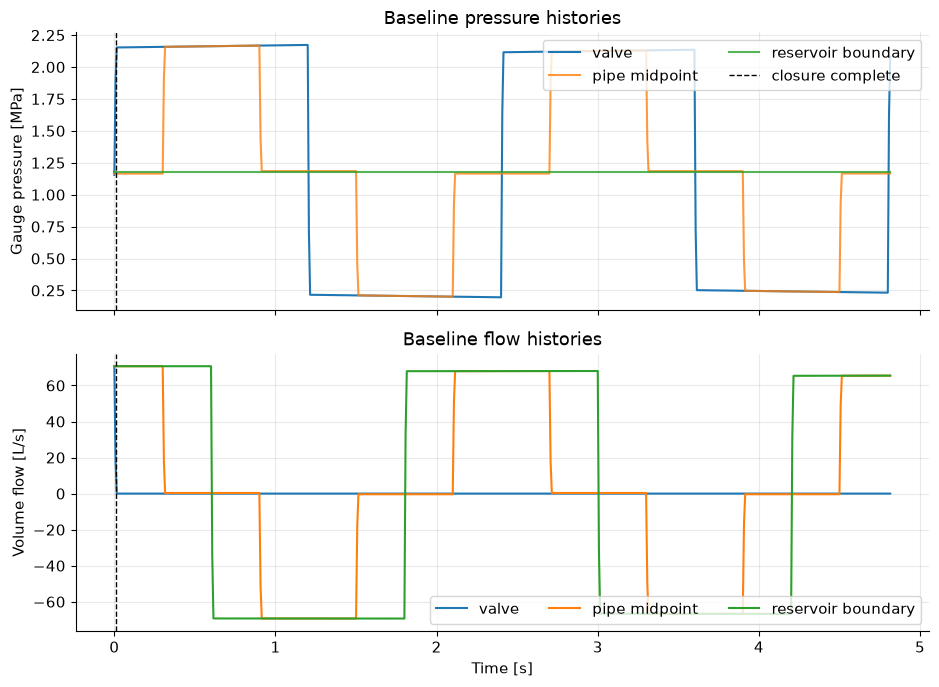

In [6]:
t = baseline["time"]
x = baseline["x"]
H = baseline["H"]
Q = baseline["Q"]
rho = baseline["density"]
mid = len(x) // 2

fig, axes = plt.subplots(2, 1, figsize=(9.5, 7), sharex=True)
axes[0].plot(t, rho*g*H[:, -1]/1e6, label="valve")
axes[0].plot(t, rho*g*H[:, mid]/1e6, label="pipe midpoint", alpha=0.8)
axes[0].plot(t, rho*g*H[:, 0]/1e6, label="reservoir boundary", alpha=0.8)
axes[0].axvline(baseline["closure_time"], color="k", ls="--", lw=1, label="closure complete")
axes[0].set(ylabel="Gauge pressure [MPa]", title="Baseline pressure histories")
axes[0].legend(ncol=2)

axes[1].plot(t, 1e3*Q[:, -1], label="valve")
axes[1].plot(t, 1e3*Q[:, mid], label="pipe midpoint")
axes[1].plot(t, 1e3*Q[:, 0], label="reservoir boundary")
axes[1].axvline(baseline["closure_time"], color="k", ls="--", lw=1)
axes[1].set(xlabel="Time [s]", ylabel="Volume flow [L/s]",
            title="Baseline flow histories")
axes[1].legend(ncol=3)
plt.tight_layout()
plt.show()

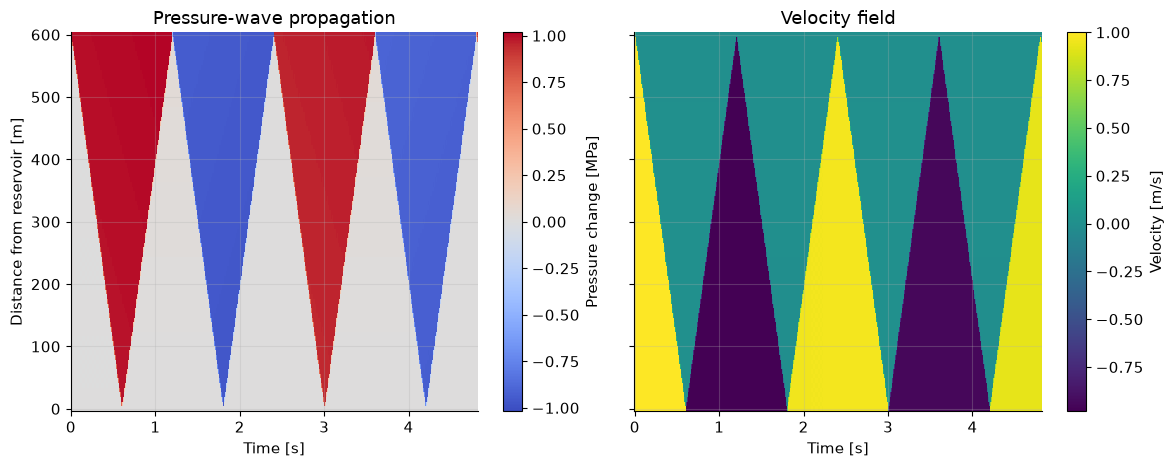

In [7]:
delta_p = rho * g * (H - baseline["H_initial"][None, :]) / 1e6
velocity = Q / baseline["area"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
levels = np.max(abs(delta_p))
pcm0 = axes[0].pcolormesh(t, x, delta_p.T, shading="auto", cmap="coolwarm",
                          vmin=-levels, vmax=levels)
fig.colorbar(pcm0, ax=axes[0], label="Pressure change [MPa]")
axes[0].set(xlabel="Time [s]", ylabel="Distance from reservoir [m]",
            title="Pressure-wave propagation")

pcm1 = axes[1].pcolormesh(t, x, velocity.T, shading="auto", cmap="viridis")
fig.colorbar(pcm1, ax=axes[1], label="Velocity [m/s]")
axes[1].set(xlabel="Time [s]", title="Velocity field")
plt.tight_layout()
plt.show()

### Interpretation check

The diagonal bands have slope $dx/dt=\pm a$. The first compression wave moves from the valve toward the reservoir. The constant-head reservoir reflects it as a pressure-relief wave. Flow can reverse locally after reflections even though the valve remains closed.

The prescribed valve flow reaches zero exactly at $T_c$. This is a useful boundary for learning wave mechanics, but “valve opening fraction” and flow fraction are not generally identical in a real system.

## Exercise 4 — slider investigation

Move one slider at a time and record evidence for the statements below. Slider updates occur when you release the control.

1. Set $T_c$ just below, close to, and well above $2L/a$. What happens to the maximum valve pressure?
2. Double $L$ while keeping the rapid-closure ratio below one. Does the first Joukowsky rise change? What timing does change?
3. Increase $a$. Explain the changes in both pressure rise and wave period.
4. Increase $D$ at fixed initial velocity. Compare pressure amplitude and volume flow.
5. Increase $f$. Which part of the trace changes most clearly?
6. Find a slider combination that triggers the cavitation warning. Explain why the displayed negative-pressure continuation is then not physically trustworthy.

> If widgets do not appear, install `ipywidgets`, restart the kernel, and run the notebook again.

In [8]:
def slider(description, value, minimum, maximum, step, unit=""):
    return widgets.FloatSlider(
        description=description,
        value=value,
        min=minimum,
        max=maximum,
        step=step,
        continuous_update=False,
        readout_format=".3g",
        style={"description_width": "145px"},
        layout=widgets.Layout(width="520px"),
    )


def water_hammer_dashboard(length, diameter, wave_speed, friction_factor,
                           initial_velocity, reservoir_head, closure_time, density):
    result = simulate_water_hammer(
        length=length, diameter=diameter, wave_speed=wave_speed,
        friction_factor=friction_factor, initial_velocity=initial_velocity,
        reservoir_head=reservoir_head, closure_time=closure_time, density=density,
        n_reaches=60, n_round_trips=3,
    )
    metric = case_metrics(result)
    t, H, Q = result["time"], result["H"], result["Q"]
    pressure = density * g * H
    classification = "RAPID" if metric["closure_ratio"] < 1 else "SLOW"

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(t, pressure[:, -1]/1e6, label="valve")
    axes[0].plot(t, pressure[:, len(result["x"])//2]/1e6, label="midpoint", alpha=0.8)
    axes[0].axvline(closure_time, color="k", ls="--", lw=1)
    axes[0].set(xlabel="Time [s]", ylabel="Gauge pressure [MPa]",
                title=f"Pressure — {classification} closure")
    axes[0].legend()

    axes[1].plot(t, Q[:, -1]*1e3, label="valve")
    axes[1].plot(t, Q[:, len(result["x"])//2]*1e3, label="midpoint", alpha=0.8)
    axes[1].axvline(closure_time, color="k", ls="--", lw=1)
    axes[1].set(xlabel="Time [s]", ylabel="Volume flow [L/s]", title="Flow")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    print(f"2L/a = {result['round_trip']:.3f} s;  Tc/(2L/a) = {metric['closure_ratio']:.3f}")
    print(f"Joukowsky Δp = {density*wave_speed*initial_velocity/1e6:.3f} MPa")
    print(f"Maximum gauge pressure anywhere = {metric['maximum_gauge_pressure']/1e6:.3f} MPa")
    print(f"Minimum absolute pressure anywhere = {metric['minimum_absolute_pressure']/1e3:.1f} kPa")
    if metric["minimum_absolute_pressure"] <= p_vapour:
        print("⚠ Cavitation/column-separation risk: the single-phase result is invalid here.")


if WIDGETS_AVAILABLE:
    water_controls = {
        "length": slider("Pipe length L [m]", 600, 100, 1500, 50),
        "diameter": slider("Diameter D [m]", 0.30, 0.10, 0.80, 0.05),
        "wave_speed": slider("Wave speed a [m/s]", 1000, 500, 1400, 50),
        "friction_factor": slider("Darcy factor f [-]", 0.020, 0.000, 0.040, 0.002),
        "initial_velocity": slider("Initial V₀ [m/s]", 1.0, 0.2, 2.5, 0.1),
        "reservoir_head": slider("Reservoir head [m]", 120, 20, 200, 5),
        "closure_time": slider("Closure time Tc [s]", 0.25, 0.05, 5.00, 0.05),
        "density": slider("Density ρ [kg/m³]", 998, 800, 1200, 10),
    }
    dashboard = widgets.interactive(water_hammer_dashboard, **water_controls)
    display(dashboard)
else:
    print("Run water_hammer_dashboard(...) directly, or install ipywidgets for sliders.")

interactive(children=(FloatSlider(value=600.0, continuous_update=False, description='Pipe length L [m]', layou…

## Exercise 5 — force on a pipe bend (32–45 min)

Place a compact bend at a chosen position in the pipe. Let the inlet direction be

$$\mathbf e_1=(1,0),$$

and let the outlet turn through angle $\theta$,

$$\mathbf e_2=(\cos\theta,\sin\theta).$$

For a short bend of constant diameter, take $p_1\approx p_2=p_g(t)$ and $Q_1\approx Q_2=Q(t)$. A quasi-steady momentum balance gives the force of the fluid on the bend as

$$
\boxed{\mathbf F_{f\rightarrow b}
=\left[p_gA+\frac{\rho Q^2}{A}\right](\mathbf e_1-\mathbf e_2)}.
$$

Therefore,

$$F_x=C(1-\cos\theta),\qquad F_y=-C\sin\theta,$$

where

$$C=p_gA+\frac{\rho Q^2}{A}.$$

The support reaction required to hold the bend is opposite to $\mathbf F_{f\rightarrow b}$, before adding weight, external loads and structural dynamics. We use **gauge** pressure because external atmospheric pressure acts on the outside of the pipe.

### Assumptions in this bend estimate

- the elbow is short relative to the acoustic wavelength;
- pressure is approximately equal at its two ports;
- bend loss, gravity and the unsteady momentum stored inside the elbow are neglected;
- the pipe/support structure is rigid in the hydraulic calculation;
- the displayed load is not a stress or code-compliant support design.

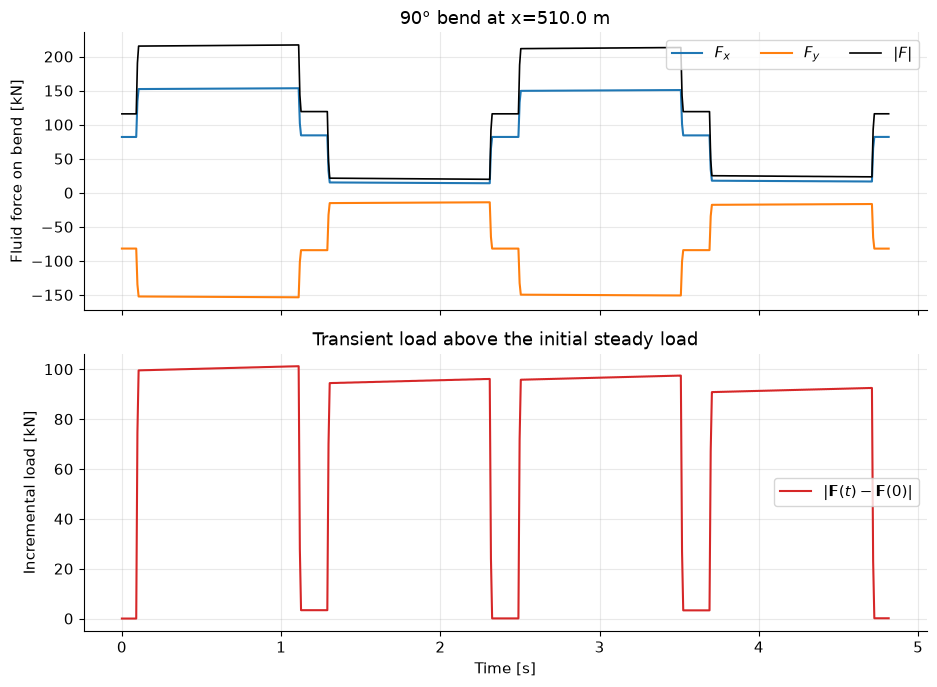

Initial force magnitude: 115.85 kN
Peak force magnitude: 217.03 kN
Peak incremental load: 101.19 kN
Peak |pressure contribution C_p|: 153.47 kN
Peak momentum contribution C_m: 0.07 kN


In [9]:
def bend_force_history(result, bend_fraction=0.85, bend_angle_deg=90.0):
    """Quasi-steady fluid force on a constant-diameter bend."""
    idx = int(np.clip(round(bend_fraction * (len(result["x"]) - 1)),
                      0, len(result["x"]) - 1))
    H_b = result["H"][:, idx]
    Q_b = result["Q"][:, idx]
    rho = result["density"]
    A = result["area"]
    theta = np.radians(bend_angle_deg)

    pressure_term = rho * g * H_b * A
    momentum_term = rho * Q_b**2 / A
    coefficient = pressure_term + momentum_term
    Fx = coefficient * (1 - np.cos(theta))
    Fy = -coefficient * np.sin(theta)
    magnitude = np.hypot(Fx, Fy)
    incremental = np.hypot(Fx - Fx[0], Fy - Fy[0])
    return {
        "index": idx,
        "x": result["x"][idx],
        "Fx": Fx,
        "Fy": Fy,
        "magnitude": magnitude,
        "incremental": incremental,
        "pressure_term": pressure_term,
        "momentum_term": momentum_term,
    }


bend0 = bend_force_history(baseline, bend_fraction=0.85, bend_angle_deg=90)
t = baseline["time"]

fig, axes = plt.subplots(2, 1, figsize=(9.5, 7), sharex=True)
axes[0].plot(t, bend0["Fx"]/1e3, label=r"$F_x$")
axes[0].plot(t, bend0["Fy"]/1e3, label=r"$F_y$")
axes[0].plot(t, bend0["magnitude"]/1e3, color="k", lw=1.2, label=r"$|F|$")
axes[0].set(ylabel="Fluid force on bend [kN]",
            title=f"90° bend at x={bend0['x']:.1f} m")
axes[0].legend(ncol=3)

axes[1].plot(t, bend0["incremental"]/1e3, color="C3",
             label=r"$|\mathbf{F}(t)-\mathbf{F}(0)|$")
axes[1].set(xlabel="Time [s]", ylabel="Incremental load [kN]",
            title="Transient load above the initial steady load")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Initial force magnitude: {bend0['magnitude'][0]/1e3:.2f} kN")
print(f"Peak force magnitude: {bend0['magnitude'].max()/1e3:.2f} kN")
print(f"Peak incremental load: {bend0['incremental'].max()/1e3:.2f} kN")
print(f"Peak |pressure contribution C_p|: {np.max(abs(bend0['pressure_term']))/1e3:.2f} kN")
print(f"Peak momentum contribution C_m: {bend0['momentum_term'].max()/1e3:.2f} kN")

### Bend investigation

Use the sliders below, then answer:

1. Compare the pressure and momentum terms. Which dominates for the baseline case?
2. Change the bend from 30° to 90° to 150°. Compare with the factor $2\sin(\theta/2)$.
3. Move the bend from 20% to 90% of the pipe length. Does peak load necessarily change, or mainly its arrival time?
4. Double $D$ at fixed $V_0$. Explain why bend force changes strongly even when the ideal pressure rise does not.
5. Increase $T_c$ until the peak incremental load is less than half the baseline value.
6. State the direction of the required support reaction at the first compression peak.

In [10]:
def bend_dashboard(diameter, closure_time, bend_position, bend_angle,
                   initial_velocity, wave_speed):
    result = simulate_water_hammer(
        diameter=diameter, closure_time=closure_time,
        initial_velocity=initial_velocity, wave_speed=wave_speed,
        n_reaches=60, n_round_trips=3,
    )
    force = bend_force_history(result, bend_position, bend_angle)
    t = result["time"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(t, force["Fx"]/1e3, label=r"$F_x$")
    axes[0].plot(t, force["Fy"]/1e3, label=r"$F_y$")
    axes[0].plot(t, force["magnitude"]/1e3, color="k", label=r"$|F|$")
    axes[0].set(xlabel="Time [s]", ylabel="Force [kN]",
                title=f"Fluid force at x={force['x']:.0f} m")
    axes[0].legend()

    axes[1].plot(t, force["pressure_term"]/1e3, label=r"$p_gA$")
    axes[1].plot(t, force["momentum_term"]/1e3, label=r"$\rho Q^2/A$")
    axes[1].set(xlabel="Time [s]", ylabel="Coefficient contribution [kN]",
                title="Pressure and momentum contributions")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    print(f"Peak |F| = {force['magnitude'].max()/1e3:.2f} kN")
    print(f"Peak incremental load = {force['incremental'].max()/1e3:.2f} kN")
    print("Support reaction is equal and opposite to the plotted fluid force,"
          " before structural effects.")


if WIDGETS_AVAILABLE:
    bend_controls = {
        "diameter": slider("Diameter D [m]", 0.30, 0.10, 0.80, 0.05),
        "closure_time": slider("Closure time Tc [s]", 0.25, 0.05, 5.00, 0.05),
        "bend_position": slider("Bend position x/L", 0.85, 0.10, 0.95, 0.05),
        "bend_angle": slider("Bend angle [deg]", 90, 15, 165, 5),
        "initial_velocity": slider("Initial V₀ [m/s]", 1.0, 0.2, 2.5, 0.1),
        "wave_speed": slider("Wave speed a [m/s]", 1000, 500, 1400, 50),
    }
    bend_widget = widgets.interactive(bend_dashboard, **bend_controls)
    display(bend_widget)
else:
    print("Run bend_dashboard(...) directly, or install ipywidgets for sliders.")

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='Diameter D [m]', layout=Lay…

## Exercise 6 — engineering decision and exit ticket

Your system operates with the baseline geometry. Use evidence from the notebook to propose a safer closure strategy.

Submit five concise statements:

1. the baseline values of $2L/a$, $\Delta p_J$, maximum simulated valve pressure and peak incremental bend load;
2. a proposed valve closing time, with the resulting closure ratio $T_c/(2L/a)$;
3. the percentage reduction in maximum pressure and peak incremental bend load;
4. one check you would make for cavitation or unacceptable low pressure;
5. two model improvements needed before specifying a real valve actuator or pipe support.

### Optional extension

Replace the prescribed flow schedule with a valve equation such as

$$Q_v=C_dA_v(t)\sqrt{2gH_v},$$

and solve this nonlinear boundary condition together with the incoming characteristic. 

## Summary

- A valve closure launches a wave; it does not instantaneously change the whole pipe.
- For rapid closure, $\Delta p\approx\rho a\Delta V$.
- The ratio $T_c/(2L/a)$ is central to distinguishing rapid and slow closure.
- Pipe length mainly controls wave timing, while wave speed affects both timing and Joukowsky amplitude.
- For fixed velocity change, diameter does not enter the ideal Joukowsky pressure rise, but it strongly affects volume flow and bend load through area.
- Bend force contains pressure and momentum contributions and is a vector; the support reaction is opposite to the fluid force.
- Predictions that cross vapour pressure invalidate the single-phase model and require a cavitation/column-separation treatment.